# 会员日促销、感知价值与复购意愿：被调节的中介分析



## 1. 理论框架与研究假设
从顾客对“所得收益与所付成本”的权衡出发，会员日折扣可能降低感知货币成本，使顾客觉得购买更划算，提升感知价值；较高的感知价值可能增强再次购买意愿。价格敏感度较高的顾客更关注价格变化，因此促销力度对感知价值的正向关系可能更强。

|角色|变量|CSV 字段|
|---|---|---|
|自变量 X|会员日促销力度|promo|
|中介 M|感知价值|value|
|因变量 Y|复购意愿|repurchase|
|调节变量 W|价格敏感度|price_sens|

- H1：促销力度与感知价值正相关（在平均价格敏感度下）。
- H2：控制促销力度后，感知价值与复购意愿正相关。
- H3：在平均价格敏感度下，促销力度经感知价值与复购意愿形成正向间接关联。
- H4：价格敏感度正向调节促销力度对感知价值的关系。
- H5：价格敏感度越高，上述间接效应越强。



## 2. 方程和检验标准
令 Xc、Wc 为均值中心化变量：

$$M=i_M+a_1X_c+a_2W_c+a_3X_cW_c+e_M$$
$$Y=i_Y+c'X_c+bM+e_Y$$

条件间接效应：$IE(w)=(a_1+a_3w)b$；调节中介指数：$IMM=a_3b$。

回归报告非标准化系数、HC3 稳健标准误、双侧 p 值和 95% 置信区间；间接效应使用 5,000 次个案重抽样的百分位 Bootstrap 95% 区间。区间不包含 0 才支持相应非零效应；支持正向假设还需方向为正。

主模型遵循上式；另提供 Y 方程加入 W 的敏感性分析。

In [1]:
from pathlib import Path
import io, json, shutil, platform
import numpy as np
import pandas as pd
import scipy
import statsmodels
import statsmodels.formula.api as smf
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
from google.colab import files

OUT = Path('/content/coffee_results')
OUT.mkdir(exist_ok=True)
SEED, B = 2025, 5000
# 图中使用英文，避免 Colab 中文字体缺失；正文和字段解释为中文。
def table_output(df, name):
    display(df)
    df.to_csv(OUT / (name+'.csv'), index=False, encoding='utf-8-sig')
    shown = df.copy()
    for c in shown.select_dtypes(include='number'):
        shown[c] = shown[c].map(lambda x: f'{x:.4g}')
    fig, ax = plt.subplots(figsize=(max(9, len(df.columns)*1.5), max(2, .38*len(df)+1.2)))
    ax.axis('off')
    t=ax.table(cellText=shown.values, colLabels=shown.columns, loc='center', cellLoc='center')
    t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1,1.5)
    ax.set_title(name, pad=18)
    fig.savefig(OUT/(name+'.png'), dpi=180, bbox_inches='tight')
    plt.show()


## 3. 模型图
W 的箭头指向 X→M 路径，表示调节；图中未逐一绘出协变量主效应，估计时包含 W→M。

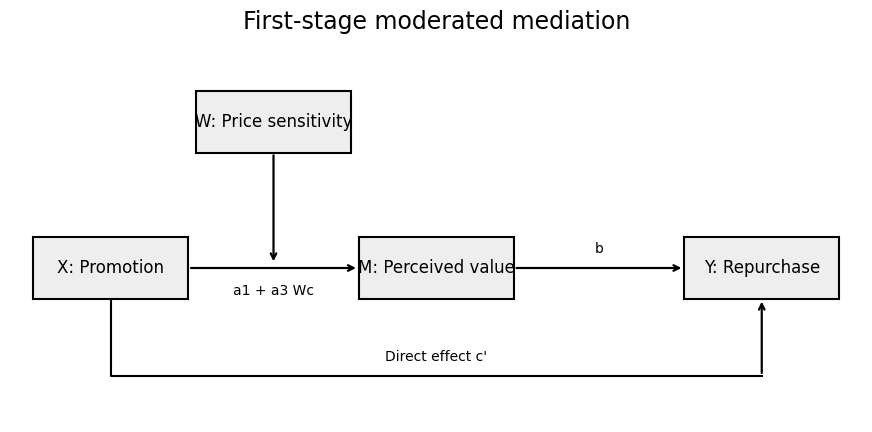

In [2]:
fig, ax = plt.subplots(figsize=(11,5))
ax.set(xlim=(0,11), ylim=(0,5)); ax.axis('off')
def box(x,y,label):
    ax.add_patch(Rectangle((x,y),2,0.8,facecolor='#eeeeee',edgecolor='black',lw=1.5))
    ax.text(x+1,y+.4,label,ha='center',va='center',fontsize=12)
def arrow(a,b): ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',lw=1.6,color='black'))
box(.3,1.6,'X: Promotion'); box(4.5,1.6,'M: Perceived value'); box(8.7,1.6,'Y: Repurchase')
box(2.4,3.5,'W: Price sensitivity')
arrow((2.3,2),(4.5,2)); arrow((6.5,2),(8.7,2)); arrow((3.4,3.5),(3.4,2.05))
ax.text(3.4,1.65,'a1 + a3 Wc',ha='center'); ax.text(7.6,2.2,'b',ha='center')
ax.plot([1.3,1.3,9.7],[1.6,.6,.6],color='black',lw=1.5); arrow((9.7,.6),(9.7,1.6))
ax.text(5.5,.8,"Direct effect c'",ha='center')
ax.set_title('First-stage moderated mediation',fontsize=17)
fig.savefig(OUT/'01_model.png',dpi=220,bbox_inches='tight'); plt.show()


## 4. 上传和检查数据
只对四个分析字段做完整案例删除，并报告删除数量；相同答案的重复行仅提示，不自动删除。未知量表范围不强行限定为 1–5 或 1–7，不自动删除极端值。

Saving coffee_member_survey.csv to coffee_member_survey.csv


,field,missing_or_invalid
0,promo,0
1,value,0
2,repurchase,0
3,price_sens,0


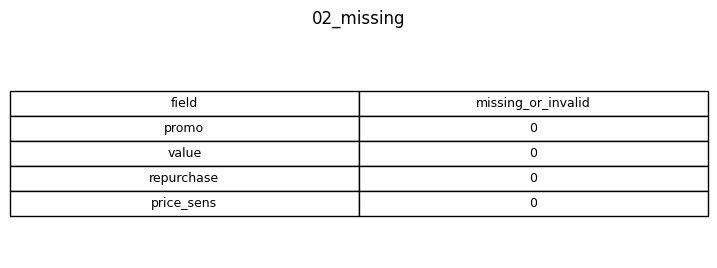

,raw_N,analysis_N,excluded_N,duplicate_response_rows
0,300,300,0,0


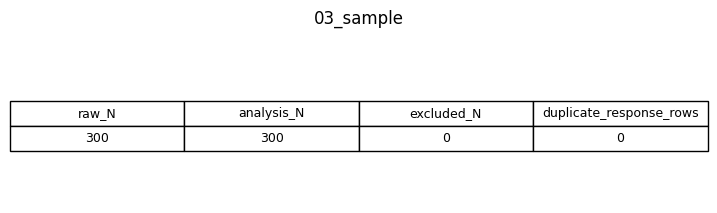

,variable,count,mean,std,min,25%,50%,75%,max
0,X,300.0,4.001000,1.010761,1.4,3.3,4.0,4.700,6.4
1,M,300.0,4.006333,0.999629,1.0,3.3,3.9,4.700,7.0
2,Y,300.0,4.005667,1.011374,1.5,3.3,3.9,4.725,6.8
3,W,300.0,4.006333,1.014507,1.3,3.3,3.9,4.700,7.0


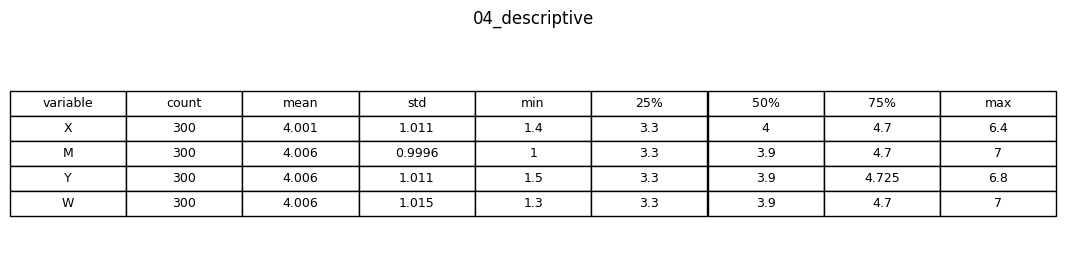

,variable,X,M,Y,W
0,X,1.000000,0.471286,0.393281,0.232021
1,M,0.471286,1.000000,0.552880,0.316128
2,Y,0.393281,0.552880,1.000000,0.196616
3,W,0.232021,0.316128,0.196616,1.000000


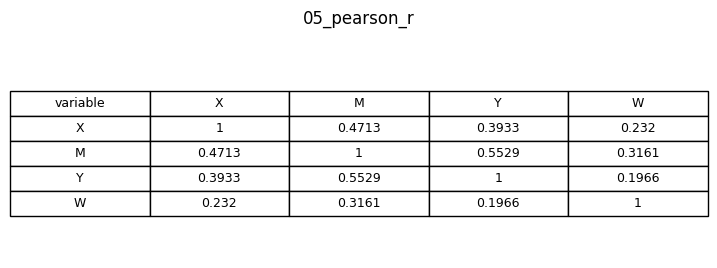

In [4]:
uploaded = files.upload()
filename = 'coffee_member_survey.csv'
if filename not in uploaded:
    raise ValueError('请上传名为 coffee_member_survey.csv 的原始文件')
raw = pd.read_csv(io.BytesIO(uploaded[filename]))
mapping={'promo':'X','value':'M','repurchase':'Y','price_sens':'W'}
assert set(mapping).issubset(raw.columns), f'字段不匹配：{raw.columns.tolist()}'
numeric=raw[list(mapping)].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
audit=pd.DataFrame({'field':list(mapping), 'missing_or_invalid':numeric.isna().sum().values})
table_output(audit,'02_missing')
d=numeric.dropna().rename(columns=mapping).copy()
table_output(pd.DataFrame({'raw_N':[len(raw)],'analysis_N':[len(d)],'excluded_N':[len(raw)-len(d)],
                           'duplicate_response_rows':[numeric.duplicated().sum()]}),'03_sample')
assert len(d)>10 and (d.std()>0).all(), '有效样本太少或存在常量变量'
xbar,wbar=d.X.mean(),d.W.mean()
d['Xc']=d.X-xbar; d['Wc']=d.W-wbar
table_output(d[['X','M','Y','W']].describe().T.reset_index(names='variable'),'04_descriptive')
table_output(d[['X','M','Y','W']].corr().reset_index(names='variable'),'05_pearson_r')


## 5. 回归检验
H1 对应 M 方程 Xc 系数，H2 对应 Y 方程 M 系数，H4 对应 Xc:Wc。总关联回归仅作描述，不要求总关联显著才检验中介。

,model,term,B,HC3_SE,p,CI_low,CI_high,R2,N
0,M_model,Intercept,3.934116,0.048635,0.000000e+00,3.838793,4.029439,0.352818,300
1,M_model,Xc,0.418563,0.052694,1.969386e-15,0.315284,0.521841,0.352818,300
2,M_model,Wc,0.190773,0.044240,1.616387e-05,0.104064,0.277482,0.352818,300
3,M_model,Xc:Wc,0.304552,0.053003,9.141805e-09,0.200668,0.408437,0.352818,300
4,Y_model,Intercept,2.090540,0.210435,2.949740e-23,1.678096,2.502985,0.328319,300
5,Y_model,Xc,0.170714,0.054444,1.715055e-03,0.064006,0.277423,0.328319,300
6,Y_model,M,0.478025,0.051043,7.598900e-21,0.377982,0.578068,0.328319,300
7,Y_with_W,Intercept,2.099811,0.213610,8.351371e-23,1.681144,2.518479,0.328385,300
8,Y_with_W,Xc,0.169795,0.055388,2.172651e-03,0.061237,0.278354,0.328385,300
9,Y_with_W,M,0.475711,0.051857,4.575377e-20,0.374074,0.577348,0.328385,300


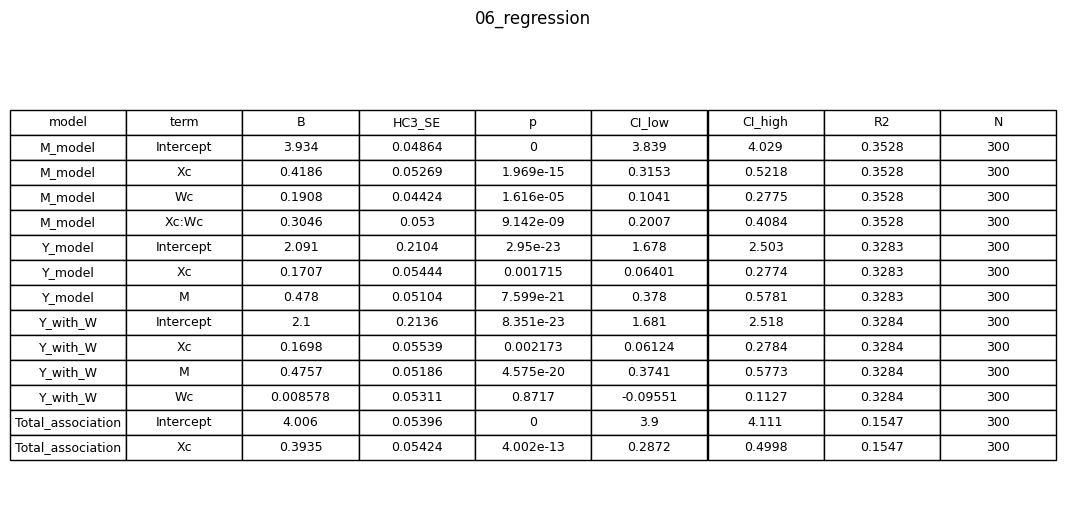

7648

In [5]:
fm=smf.ols('M ~ Xc * Wc',d).fit(cov_type='HC3')
fy=smf.ols('Y ~ Xc + M',d).fit(cov_type='HC3')
fy_w=smf.ols('Y ~ Xc + M + Wc',d).fit(cov_type='HC3')
ft=smf.ols('Y ~ Xc',d).fit(cov_type='HC3')
models={'M_model':fm,'Y_model':fy,'Y_with_W':fy_w,'Total_association':ft}
rows=[]
for name,fit in models.items():
    ci=fit.conf_int()
    for term in fit.params.index:
        rows.append([name,term,fit.params[term],fit.bse[term],fit.pvalues[term],*ci.loc[term],fit.rsquared,int(fit.nobs)])
table_output(pd.DataFrame(rows,columns=['model','term','B','HC3_SE','p','CI_low','CI_high','R2','N']),'06_regression')
(OUT/'regression_details.txt').write_text('\n\n'.join(k+'\n'+str(v.summary()) for k,v in models.items()))


## 6. 简单斜率与交互图
使用 W 的均值±1个标准差及均值；若超出观测范围，改用第16、50、84百分位。W 保持连续变量，不按高低分组回归。

,W_level,W_raw,slope,p,CI_low,CI_high
0,Low,2.991827,0.109592,1.211717e-01,-0.028998,0.248182
1,Middle,4.006333,0.418563,1.969386e-15,0.315284,0.521841
2,High,5.020840,0.727533,6.256904e-20,0.571519,0.883547


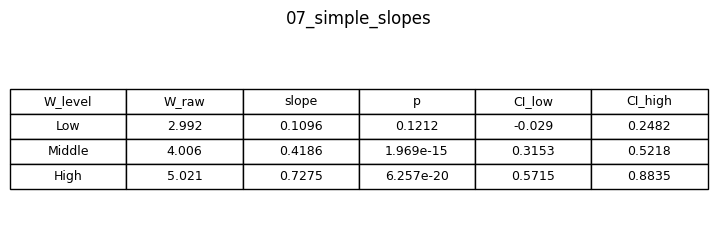

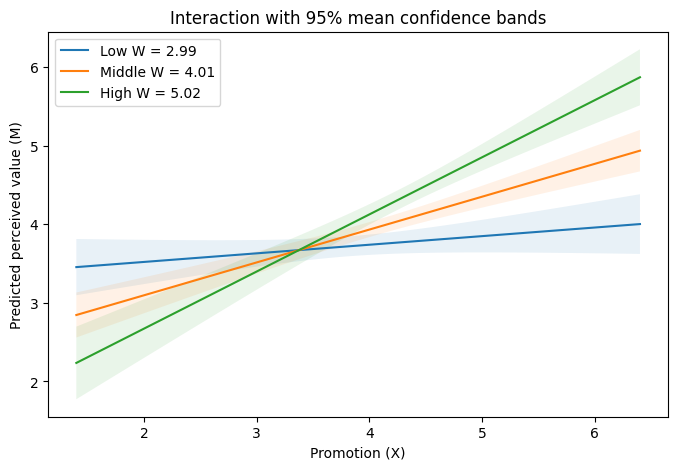

In [6]:
sdw=d.W.std()
wraw=np.array([wbar-sdw,wbar,wbar+sdw])
if (wraw.min()<d.W.min()) or (wraw.max()>d.W.max()):
    wraw=d.W.quantile([.16,.50,.84]).to_numpy()
    print('探查点改用 W 的第16、50、84百分位')
wc=wraw-wbar
slopes=[]
for label,w,wr in zip(['Low','Middle','High'],wc,wraw):
    contrast=np.zeros(len(fm.params)); contrast[fm.params.index.get_loc('Xc')]=1
    contrast[fm.params.index.get_loc('Xc:Wc')]=w
    test=fm.t_test(contrast)
    slopes.append([label,wr,float(np.asarray(test.effect).item()),float(np.asarray(test.pvalue).item()),*test.conf_int()[0]])
table_output(pd.DataFrame(slopes,columns=['W_level','W_raw','slope','p','CI_low','CI_high']),'07_simple_slopes')
fig,ax=plt.subplots(figsize=(8,5))
xx=np.linspace(d.X.min(),d.X.max(),100)
for label,w in zip(['Low','Middle','High'],wc):
    pred=fm.get_prediction(pd.DataFrame({'Xc':xx-xbar,'Wc':w})).summary_frame()
    ax.plot(xx,pred['mean'],label=f'{label} W = {w+wbar:.2f}')
    ax.fill_between(xx,pred['mean_ci_lower'],pred['mean_ci_upper'],alpha=.1)
ax.set(xlabel='Promotion (X)',ylabel='Predicted perceived value (M)',title='Interaction with 95% mean confidence bands')
ax.legend(); fig.savefig(OUT/'08_interaction.png',dpi=200,bbox_inches='tight'); plt.show()


## 7. Bootstrap 条件间接效应与调节中介指数
每次重抽样整行顾客，联合重新估计两条方程；固定原样本中心化常数及 W 探查点。使用最小二乘加快 5,000 次运算，与上述 OLS 点估计一致。敏感性分析同时对 Y 方程加入 W。奇异重抽样会跳过并报告。

有效 Bootstrap = 5000; 跳过 = 0


,effect,W_raw,estimate,Boot_SE,CI_low,CI_high,excludes_zero
0,IE_low,2.991827,0.052388,0.034478,-0.016235,0.121368,False
1,IE_middle,4.006333,0.200083,0.032071,0.140531,0.266805,True
2,IE_high,5.020840,0.347779,0.048324,0.261471,0.451868,True
3,IMM,NaN,0.145584,0.026694,0.098001,0.203795,True


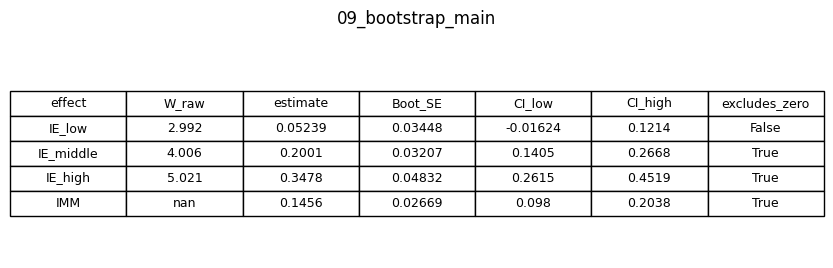

,effect,W_raw,estimate,Boot_SE,CI_low,CI_high,excludes_zero
0,IE_low,2.991827,0.052134,0.034307,-0.016187,0.120471,False
1,IE_middle,4.006333,0.199115,0.032246,0.140417,0.266377,True
2,IE_high,5.020840,0.346095,0.049042,0.256871,0.450702,True
3,IMM,NaN,0.144879,0.027017,0.096622,0.203240,True


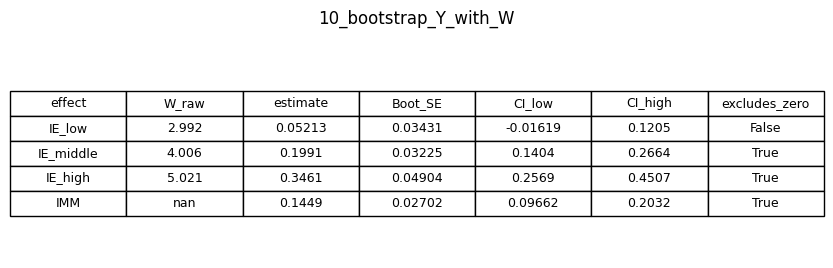

In [7]:
A=np.column_stack([np.ones(len(d)),d.Xc,d.Wc,d.Xc*d.Wc])
C=np.column_stack([np.ones(len(d)),d.Xc,d.M])
CW=np.column_stack([C,d.Wc])
m=d.M.to_numpy(); y=d.Y.to_numpy()
assert all(np.linalg.matrix_rank(z)==z.shape[1] for z in [A,C,CW]), '设计矩阵不满秩'
def effects(a,b): return np.r_[(a[1]+a[3]*wc)*b,a[3]*b]
point=effects(np.asarray(fm.params),fy.params['M'])
point_w=effects(np.asarray(fm.params),fy_w.params['M'])
rng=np.random.default_rng(SEED)
boot=[]; boot_w=[]; attempts=0
while len(boot)<B and attempts<B*2:
    attempts+=1
    idx=rng.integers(0,len(d),len(d))
    if any(np.linalg.matrix_rank(z[idx])<z.shape[1] for z in [A,C,CW]): continue
    aa=np.linalg.lstsq(A[idx],m[idx],rcond=None)[0]
    bb=np.linalg.lstsq(C[idx],y[idx],rcond=None)[0][2]
    bbw=np.linalg.lstsq(CW[idx],y[idx],rcond=None)[0][2]
    boot.append(effects(aa,bb)); boot_w.append(effects(aa,bbw))
assert len(boot)==B, '有效重抽样不足，请检查数据'
print(f'有效 Bootstrap = {B}; 跳过 = {attempts-B}')
for name,pt,bs in [('09_bootstrap_main',point,boot),('10_bootstrap_Y_with_W',point_w,boot_w)]:
    low,high=np.percentile(bs,[2.5,97.5],axis=0)
    tab=pd.DataFrame({'effect':['IE_low','IE_middle','IE_high','IMM'],
        'W_raw':list(wraw)+[np.nan],'estimate':pt,'Boot_SE':np.std(bs,axis=0,ddof=1),
        'CI_low':low,'CI_high':high,'excludes_zero':(low>0)|(high<0)})
    table_output(tab,name)
np.savez_compressed(OUT/'bootstrap_draws.npz',main=np.asarray(boot),Y_with_W=np.asarray(boot_w))




## 8. 导出结果
最后单元会打包所有表格 CSV、结果图片、模型图、完整回归输出和运行设置。Colab 菜单“文件→下载→下载 .ipynb”可以保存带真实输出的 notebook。

In [8]:
settings={'seed':SEED,'bootstrap':B,'N':len(d),'X_mean':xbar,'W_mean':wbar,'W_probes':wraw.tolist(),
          'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'scipy':scipy.__version__,'statsmodels':statsmodels.__version__,'matplotlib':matplotlib.__version__}
(OUT/'run_settings.json').write_text(json.dumps(settings,ensure_ascii=False,indent=2),encoding='utf-8')
archive=shutil.make_archive('/content/coffee_results','zip',OUT)
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>